## Create modelling function

The numpy module of Python provides a function called numpy. ravel, which is used to change a 2-dimensional array or a multi-dimensional array into a contiguous flattened array. The returned array has the same data type as the source array or input array.

In [15]:
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

def train_logistics_model(size):
    
    # Create features and target data
    X = np.random.normal(size=size).reshape(size, 1)
    y = np.vectorize(generate_data)(X).reshape(size, 1)
    
    # Create model 
    model = LogisticRegression()
    model.fit(X, y.ravel())
    predictions = model.predict(X)
    
    # Print results
    print(f'Coefficient: {model.coef_}')
    print(f'Intercept: {model.intercept_}')
    print(f'Accuracy', accuracy_score(y, predictions))
    
    # Plot histogram
    fig = plt.figure(figsize=(15,5))
    ax = fig.add_subplot(1, 2, 1)
    ax.hist(X, bins=20, alpha=0.5)
    
    # Plot logistics function based on model coefficient & intercepts
    x = np.linspace(-5, 5, 500)
    loss = compute_predictions(model, x).ravel()
    ax = fig.add_subplot(1, 2, 2)
    ax.plot(x, loss, color='red')
            
    # Plot horizontal and vertical lines for cutoff
    cutting_point = (-1, compute_prediction(model, -1))
    ax.vlines(cutting_point[0], -0.1, cutting_point[1], linestyle='dashed')
    ax.hlines(cutting_point[1], -6, cutting_point[0], linestyle='dashed')
    
    # Configure axes limits and labels
    ax.set_xlim((-5.5, 5.5))
    ax.set_ylim((-0.1, 0.1))
    ax.set_xticks((-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5))
    ax.set_yticks((0, 0.25, 0.5, 0.75, 1))
    
    plt.tight_layout()
    plt.show()
    
def generate_data(x):
    if x <= -1:
        return 0 
    else:
        return 1 

def logistics(x):
    return 1 / (1 +np.exp(-x))

def compute_predictions(model, x):
    return logistics(x * model.coef_ + model.intercept_)

Coefficient: [[3.24873056]]
Intercept: [3.82203159]
Accuracy 0.96


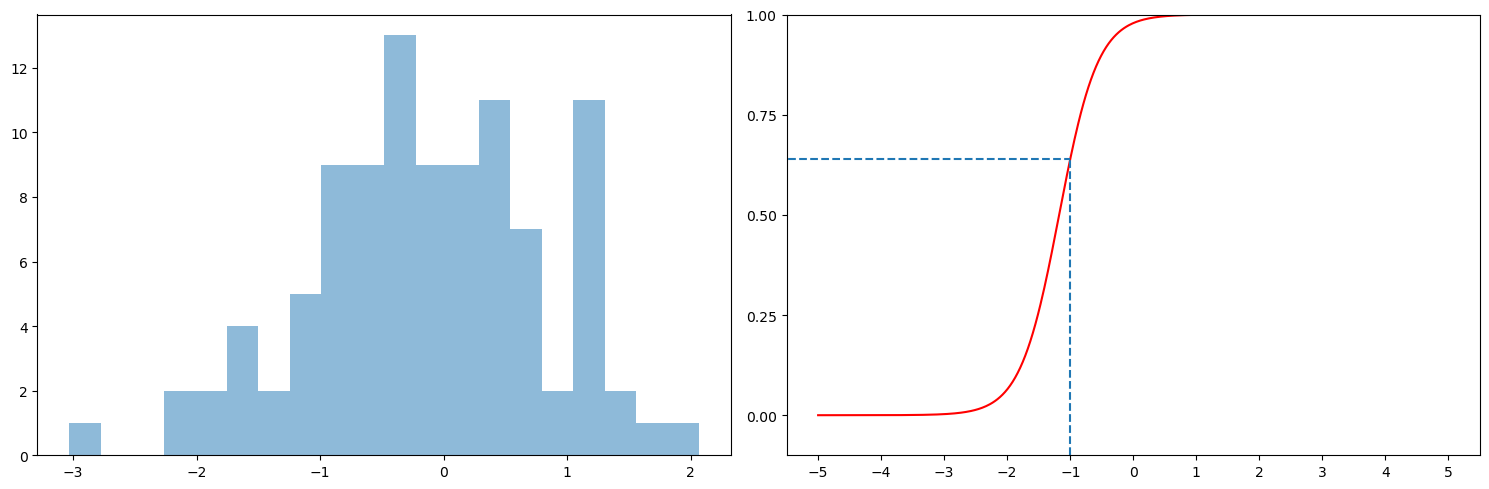

Coefficient: [[7.01693759]]
Intercept: [7.23651637]
Accuracy 0.994


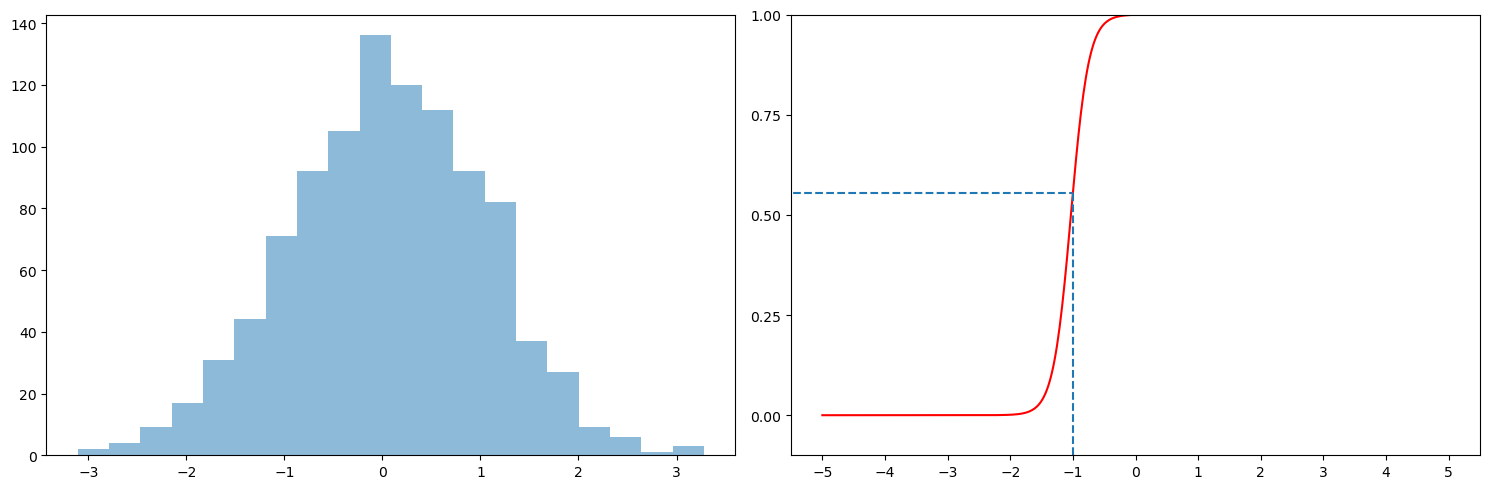

Coefficient: [[15.98561707]]
Intercept: [16.10939227]
Accuracy 0.9984


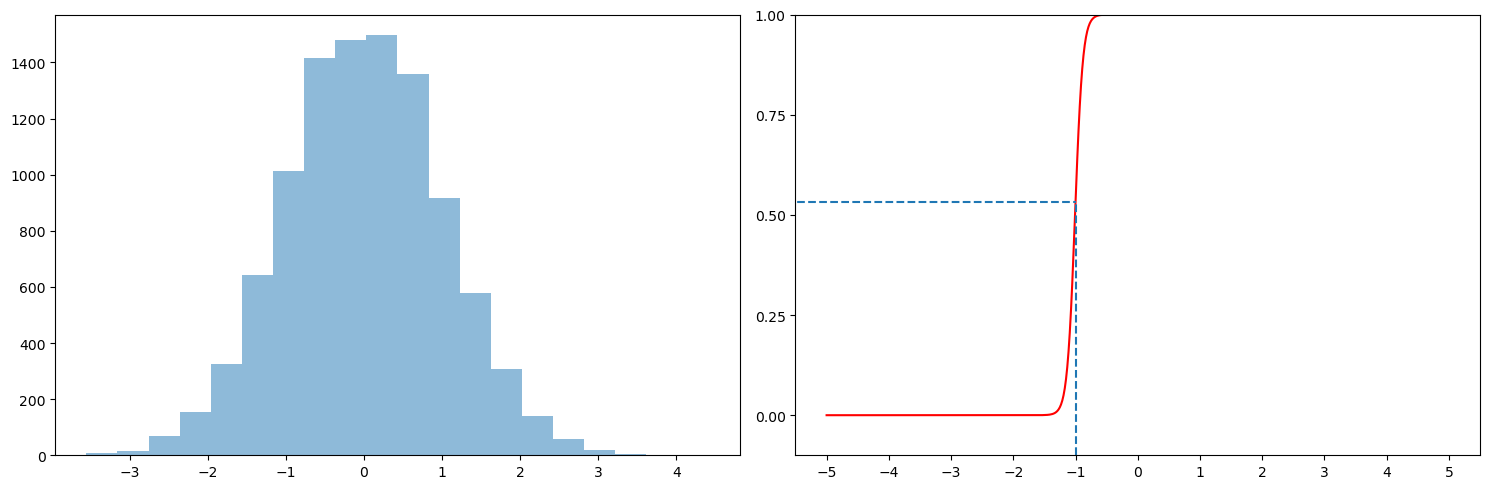

Coefficient: [[33.96653238]]
Intercept: [34.01780559]
Accuracy 0.99975


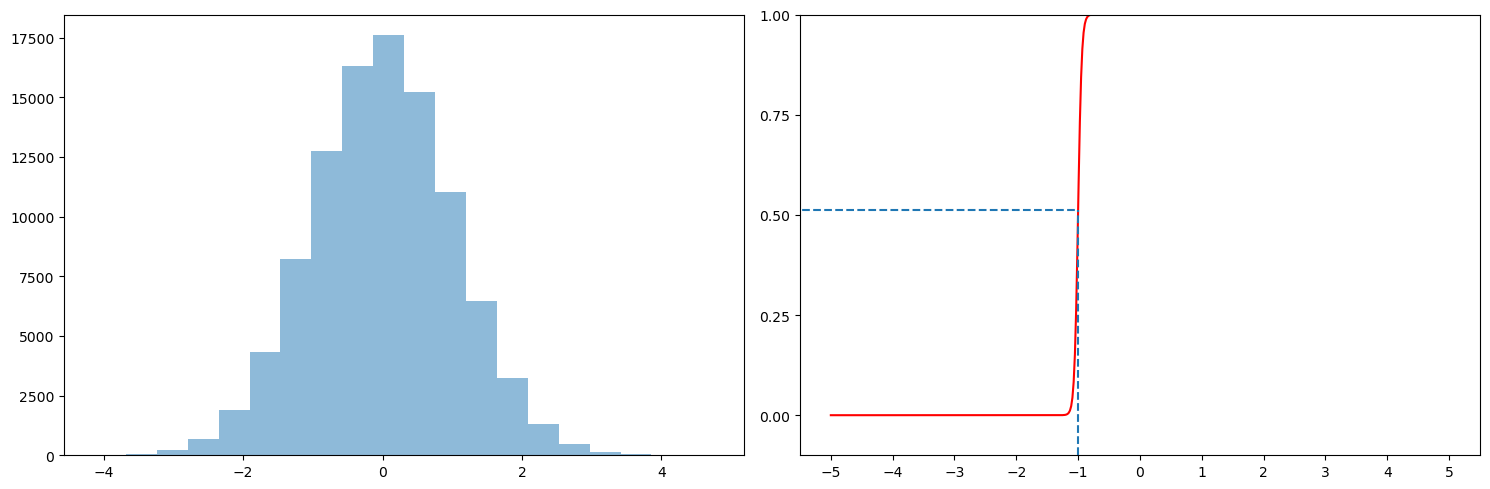

In [16]:
train_logistics_model(100)
train_logistics_model(1000)
train_logistics_model(10000)
train_logistics_model(100000)
